# Jet Engine Remaining Useful Life (RUL) Prediction
### NASA C-MAPSS — FD001 | Classical Machine Learning | End-to-End Project

**Objective:** Predict the remaining operating cycles (RUL) of a simulated turbofan engine from its sensor history, compare classical regression models, evaluate on held-out engines, and prepare a Streamlit demo.

**Dataset:** NASA C-MAPSS FD001. The dataset contains run-to-failure training trajectories and truncated test trajectories with a separate RUL label for each test engine.

> **Important:** This notebook downloads the dataset and computes all metrics from the actual run. Do not copy or invent performance values. The dataset is simulated benchmark data, not live aircraft telemetry.

**Workflow**
1. Download and inspect data
2. Exploratory Data Analysis (EDA)
3. Create RUL target for training engines
4. Feature engineering using past/current observations only
5. Split by engine to avoid engine-level leakage
6. Train and tune at least four classical ML regressors
7. Evaluate on the untouched NASA test set
8. Explain results and maintenance-alert behavior
9. Export model and create a Streamlit application


## 0. Environment setup
Run this cell once at the beginning of the Colab session.

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import os
import zipfile
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Environment ready.")

Environment ready.


## 1. Download NASA C-MAPSS and load FD001

The code first tries NASA's public dataset archive. If NASA's legacy URL is unavailable, it tries the NASA Prognostics Data Repository mirror. The archive is saved in the Colab runtime.

In [3]:
DATA_DIR = Path("/content/cmapss_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = DATA_DIR / "CMAPSSData.zip"

dataset_urls = [
    "https://data.nasa.gov/docs/legacy/CMAPSSData.zip",
    "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip",
]

if not ZIP_PATH.exists():
    last_error = None
    for url in dataset_urls:
        try:
            print(f"Trying: {url}")
            urllib.request.urlretrieve(url, ZIP_PATH)
            if ZIP_PATH.stat().st_size > 100_000:
                print("Download completed.")
                break
        except Exception as exc:
            last_error = exc
            print("Download failed:", exc)
    else:
        raise RuntimeError(
            "Could not download the dataset automatically. "
            "Download the NASA C-MAPSS ZIP manually and upload it to Colab."
        ) from last_error

EXTRACT_DIR = DATA_DIR / "extracted"
EXTRACT_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

print("Extracted files:")
for p in sorted(EXTRACT_DIR.rglob("*")):
    if p.is_file() and p.suffix.lower() == ".txt":
        print(p.name, "->", p)

Trying: https://data.nasa.gov/docs/legacy/CMAPSSData.zip
Download completed.
Extracted files:
RUL_FD001.txt -> /content/cmapss_data/extracted/RUL_FD001.txt
RUL_FD002.txt -> /content/cmapss_data/extracted/RUL_FD002.txt
RUL_FD003.txt -> /content/cmapss_data/extracted/RUL_FD003.txt
RUL_FD004.txt -> /content/cmapss_data/extracted/RUL_FD004.txt
readme.txt -> /content/cmapss_data/extracted/readme.txt
test_FD001.txt -> /content/cmapss_data/extracted/test_FD001.txt
test_FD002.txt -> /content/cmapss_data/extracted/test_FD002.txt
test_FD003.txt -> /content/cmapss_data/extracted/test_FD003.txt
test_FD004.txt -> /content/cmapss_data/extracted/test_FD004.txt
train_FD001.txt -> /content/cmapss_data/extracted/train_FD001.txt
train_FD002.txt -> /content/cmapss_data/extracted/train_FD002.txt
train_FD003.txt -> /content/cmapss_data/extracted/train_FD003.txt
train_FD004.txt -> /content/cmapss_data/extracted/train_FD004.txt


In [4]:
# FD001 contains 3 operating settings and 21 sensor measurements.
columns = (
    ["unit_number", "time_cycles"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

def find_file(filename):
    matches = list(EXTRACT_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not find {filename} in {EXTRACT_DIR}")
    return matches[0]

train_path = find_file("train_FD001.txt")
test_path = find_file("test_FD001.txt")
rul_path = find_file("RUL_FD001.txt")

train_raw = pd.read_csv(train_path, sep=r"\s+", header=None)
test_raw = pd.read_csv(test_path, sep=r"\s+", header=None)
rul_test = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL"])

assert train_raw.shape[1] == len(columns), f"Unexpected train columns: {train_raw.shape}"
assert test_raw.shape[1] == len(columns), f"Unexpected test columns: {test_raw.shape}"

train_df = train_raw.copy()
test_df = test_raw.copy()
train_df.columns = columns
test_df.columns = columns

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Test RUL shape:", rul_test.shape)
display(train_df.head())

Train shape: (20631, 26)
Test shape: (13096, 26)
Test RUL shape: (100, 1)


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Data understanding and quality checks

In [5]:
print("Train engines:", train_df["unit_number"].nunique())
print("Test engines:", test_df["unit_number"].nunique())
print("Train missing values:", int(train_df.isna().sum().sum()))
print("Test missing values:", int(test_df.isna().sum().sum()))
print("Train duplicate rows:", int(train_df.duplicated().sum()))
print("Test duplicate rows:", int(test_df.duplicated().sum()))

display(train_df.describe().T)

Train engines: 100
Test engines: 100
Train missing values: 0
Test missing values: 0
Train duplicate rows: 0
Test duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
time_cycles,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


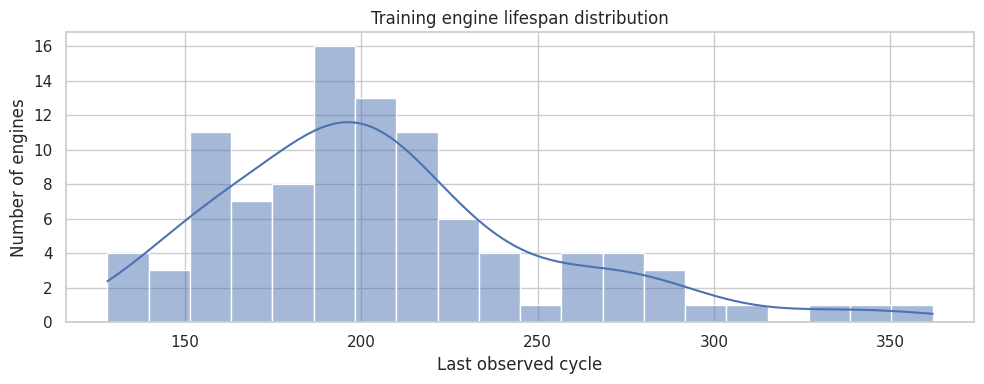

,last_cycle
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


In [6]:
train_life = train_df.groupby("unit_number")["time_cycles"].max()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(train_life, bins=20, kde=True, ax=ax)
ax.set(title="Training engine lifespan distribution", xlabel="Last observed cycle", ylabel="Number of engines")
plt.tight_layout()
plt.show()

display(train_life.describe().to_frame("last_cycle"))

### 2.1 Sensor trends for one example engine

Sensor values are on different scales, so inspect them separately. A single sensor does not necessarily decrease monotonically as an engine degrades.

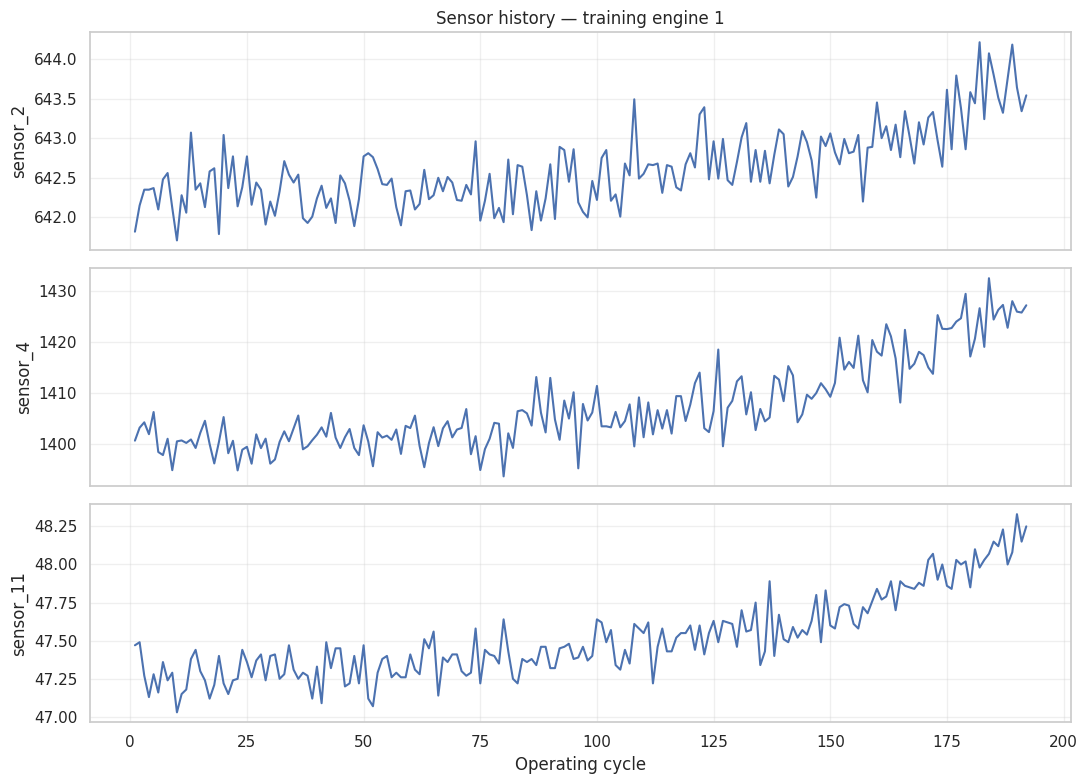

In [7]:
example_engine = int(train_df["unit_number"].iloc[0])
example = train_df[train_df["unit_number"] == example_engine].sort_values("time_cycles")

selected_sensors = ["sensor_2", "sensor_4", "sensor_11"]
fig, axes = plt.subplots(len(selected_sensors), 1, figsize=(11, 8), sharex=True)

for ax, sensor in zip(axes, selected_sensors):
    ax.plot(example["time_cycles"], example[sensor], linewidth=1.5)
    ax.set_ylabel(sensor)
    ax.grid(True, alpha=0.3)

axes[0].set_title(f"Sensor history — training engine {example_engine}")
axes[-1].set_xlabel("Operating cycle")
plt.tight_layout()
plt.show()

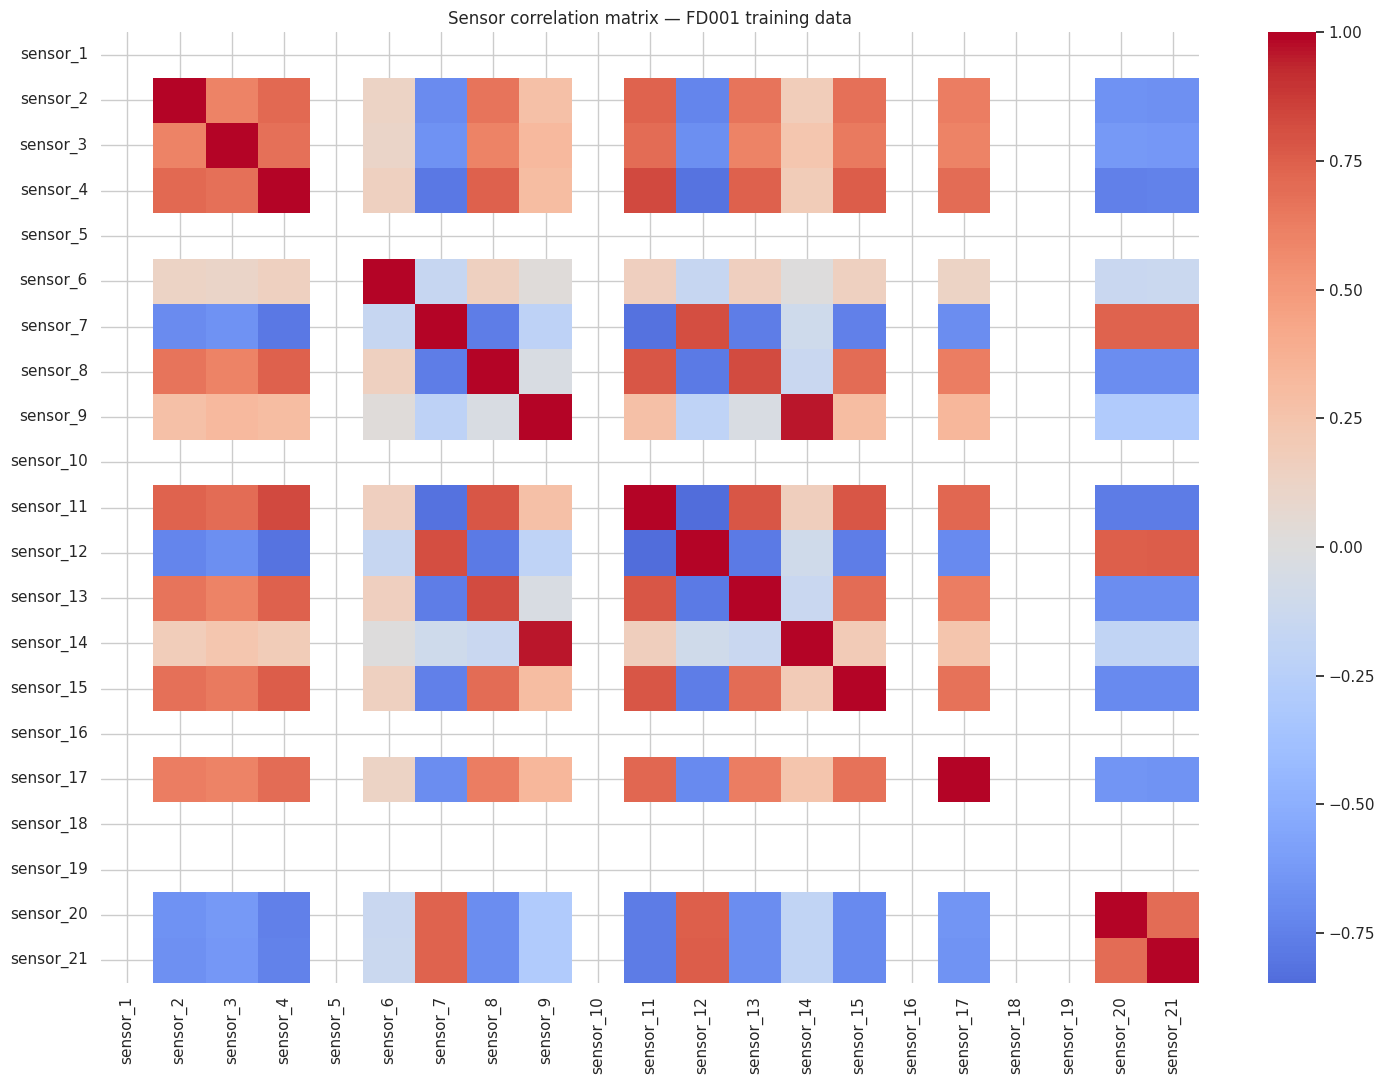

In [8]:
sensor_cols = [c for c in train_df.columns if c.startswith("sensor_")]
corr = train_df[sensor_cols].corr()

plt.figure(figsize=(15, 11))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Sensor correlation matrix — FD001 training data")
plt.tight_layout()
plt.show()

In [9]:
feature_cols_initial = [c for c in train_df.columns if c.startswith("setting_") or c.startswith("sensor_")]
feature_variance = train_df[feature_cols_initial].var()
constant_features = feature_variance[feature_variance <= 1e-12].index.tolist()

print("Constant / near-constant features:", constant_features)
print("Count:", len(constant_features))
display(feature_variance.sort_values().head(10).to_frame("variance"))

Constant / near-constant features: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Count: 7


,variance
setting_3,0.000000e+00
sensor_19,0.000000e+00
sensor_18,0.000000e+00
sensor_16,2.422479e-28
sensor_10,2.172333e-25
sensor_5,1.152399e-23
sensor_1,4.273435e-21
setting_2,8.588541e-08
sensor_6,1.929279e-06
setting_1,4.784340e-06


## 3. Create the RUL target for training data

For each training engine, the run-to-failure trajectory ends at its observed final cycle:

\[
RUL_{i,t} = T_i - t
\]

where \(T_i\) is the final cycle of training engine \(i\), and \(t\) is the current cycle.

**Do not use this formula to label the test file.** Test trajectories are truncated; NASA supplies one true RUL value for the final observed row of each test engine in `RUL_FD001.txt`.

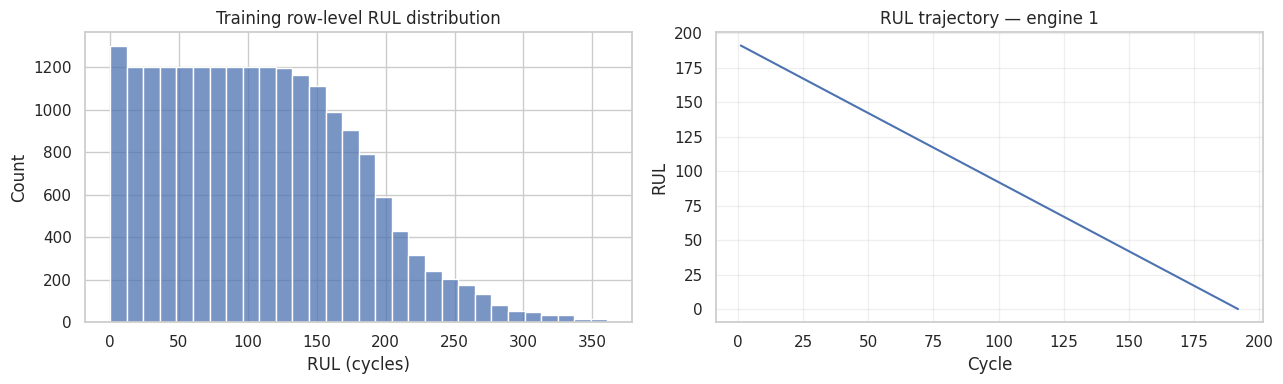

,unit_number,time_cycles,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


In [10]:
last_cycle_by_engine = train_df.groupby("unit_number")["time_cycles"].max()
train_df["RUL"] = train_df["unit_number"].map(last_cycle_by_engine) - train_df["time_cycles"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train_df["RUL"], bins=30, ax=axes[0])
axes[0].set(title="Training row-level RUL distribution", xlabel="RUL (cycles)")
engine_1 = train_df[train_df["unit_number"] == example_engine].sort_values("time_cycles")
axes[1].plot(engine_1["time_cycles"], engine_1["RUL"])
axes[1].set(title=f"RUL trajectory — engine {example_engine}", xlabel="Cycle", ylabel="RUL")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(train_df[["unit_number", "time_cycles", "RUL"]].head(10))

## 4. Feature engineering

We build features for every engine-cycle row from:
- Current sensor and operating-setting readings
- Recent rolling mean and standard deviation
- Difference from the previous cycle

All rolling calculations are grouped by engine and use the current and previous observations only (`center=False`). No future sensor readings are used.

The engine ID is retained only for splitting/grouping and is **not** used as a model feature.

In [11]:
def make_features(df, sensor_setting_columns, windows=(5, 10, 20)):
    out = df[["unit_number", "time_cycles"] + sensor_setting_columns].copy()
    out = out.sort_values(["unit_number", "time_cycles"]).reset_index(drop=True)

    grouped = out.groupby("unit_number", sort=False)

    for col in sensor_setting_columns:
        # Previous-cycle change; first cycle per engine has no previous reading.
        out[f"{col}_diff1"] = grouped[col].diff(1)

        for window in windows:
            rolling = grouped[col].rolling(window=window, min_periods=1)
            out[f"{col}_rollmean_{window}"] = (
                rolling.mean().reset_index(level=0, drop=True).sort_index()
            )
            out[f"{col}_rollstd_{window}"] = (
                rolling.std().reset_index(level=0, drop=True).sort_index()
            )

    out = out.drop(columns=["unit_number"])
    return out

base_features = [
    c for c in train_df.columns
    if c.startswith("setting_") or c.startswith("sensor_")
]
base_features = [c for c in base_features if c not in constant_features]

X_all = make_features(train_df, base_features)
y_all = train_df["RUL"].astype(float).reset_index(drop=True)
groups_all = train_df["unit_number"].reset_index(drop=True)

# Ensure row order remains aligned.
assert len(X_all) == len(y_all) == len(groups_all)
print("Engine-cycle feature matrix:", X_all.shape)
display(X_all.head())

Engine-cycle feature matrix: (20631, 137)


,time_cycles,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,setting_1_diff1,setting_1_rollmean_5,setting_1_rollstd_5,setting_1_rollmean_10,setting_1_rollstd_10,setting_1_rollmean_20,setting_1_rollstd_20,...,sensor_15_rollmean_10,sensor_15_rollstd_10,sensor_15_rollmean_20,sensor_15_rollstd_20,sensor_17_diff1,sensor_17_rollmean_5,sensor_17_rollstd_5,sensor_17_rollmean_10,sensor_17_rollstd_10,sensor_17_rollmean_20,sensor_17_rollstd_20,sensor_20_diff1,sensor_20_rollmean_5,sensor_20_rollstd_5,sensor_20_rollmean_10,sensor_20_rollstd_10,sensor_20_rollmean_20,sensor_20_rollstd_20,sensor_21_diff1,sensor_21_rollmean_5,sensor_21_rollstd_5,sensor_21_rollmean_10,sensor_21_rollstd_10,sensor_21_rollmean_20,sensor_21_rollstd_20
0,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,NaN,-0.000700,NaN,-0.000700,NaN,-0.000700,NaN,...,8.419500,NaN,8.419500,NaN,NaN,392.000000,NaN,392.000000,NaN,392.000000,NaN,NaN,39.060000,NaN,39.060000,NaN,39.060000,NaN,NaN,23.419000,NaN,23.419000,NaN,23.419000,NaN
1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,0.0026,0.000600,0.001838,0.000600,0.001838,0.000600,0.001838,...,8.425650,0.008697,8.425650,0.008697,0.0,392.000000,0.000000,392.000000,0.000000,392.000000,0.000000,-0.06,39.030000,0.042426,39.030000,0.042426,39.030000,0.042426,0.0046,23.421300,0.003253,23.421300,0.003253,23.421300,0.003253
2,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,-0.0062,-0.001033,0.003113,-0.001033,0.003113,-0.001033,0.003113,...,8.423033,0.007640,8.423033,0.007640,-2.0,391.333333,1.154701,391.333333,1.154701,391.333333,1.154701,-0.05,39.003333,0.055076,39.003333,0.055076,39.003333,0.055076,-0.0794,23.395600,0.044573,23.395600,0.044573,23.395600,0.044573
3,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,0.0050,-0.000600,0.002686,-0.000600,0.002686,-0.000600,0.002686,...,8.409325,0.028117,8.409325,0.028117,2.0,391.500000,1.000000,391.500000,1.000000,391.500000,1.000000,-0.07,38.972500,0.076322,38.972500,0.076322,38.972500,0.076322,0.0297,23.390175,0.037977,23.390175,0.037977,23.390175,0.037977
4,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,-0.0026,-0.000860,0.002397,-0.000860,0.002397,-0.000860,0.002397,...,8.413340,0.025953,8.413340,0.025953,1.0,391.800000,1.095445,391.800000,1.095445,391.800000,1.095445,0.02,38.958000,0.073621,38.958000,0.073621,38.958000,0.073621,0.0305,23.393020,0.033498,23.393020,0.033498,23.393020,0.033498


### 4.1 Optional RUL capping

Some C-MAPSS benchmark studies cap early-life RUL at 125 cycles. This is a modeling convention, not a measured fact about the engine. We keep **uncapped RUL as the primary target** in this notebook so the target definition stays transparent. You can later run a separate experiment with `y_cap = y.clip(upper=125)`.

In [12]:
print("RUL minimum:", y_all.min())
print("RUL maximum:", y_all.max())
print("RUL median:", y_all.median())

RUL minimum: 0.0
RUL maximum: 361.0
RUL median: 103.0


## 5. Split training engines into train and validation sets

We split by `unit_number`, not by individual rows. Therefore, no engine appears in both subsets. The NASA test set remains untouched until final evaluation.

In [13]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, val_idx = next(splitter.split(X_all, y_all, groups=groups_all))

X_train = X_all.iloc[train_idx].copy()
X_val = X_all.iloc[val_idx].copy()
y_train = y_all.iloc[train_idx].copy()
y_val = y_all.iloc[val_idx].copy()
groups_train = groups_all.iloc[train_idx].copy()
groups_val = groups_all.iloc[val_idx].copy()

train_engine_ids = set(groups_train.unique())
val_engine_ids = set(groups_val.unique())

assert train_engine_ids.isdisjoint(val_engine_ids)

print("Train rows:", X_train.shape[0], "| engines:", len(train_engine_ids))
print("Validation rows:", X_val.shape[0], "| engines:", len(val_engine_ids))
print("Engine overlap:", len(train_engine_ids.intersection(val_engine_ids)))

Train rows: 16561 | engines: 80
Validation rows: 4070 | engines: 20
Engine overlap: 0


## 6. Define evaluation helpers and a baseline

We report MAE, RMSE, and R². For the validation comparison, we evaluate **the final observed cycle of each held-out engine**, matching the format of the official test labels. We also retain row-level training for learning from all labeled cycles.

In [14]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

def final_cycle_indices(raw_df, selected_indices):
    # selected_indices are positional indices in the original train_df / X_all.
    selected = raw_df.iloc[selected_indices][["unit_number", "time_cycles"]].reset_index(drop=True).copy()
    selected["_position"] = np.arange(len(selected_indices))
    last_positions = (
        selected.sort_values("time_cycles")
        .groupby("unit_number")["_position"]
        .idxmax()
        .to_numpy()
    )
    return last_positions

val_final_local = final_cycle_indices(train_df, val_idx)
X_val_final = X_val.iloc[val_final_local]
y_val_final = y_val.iloc[val_final_local]

print("Validation final-engine samples:", len(y_val_final))

Validation final-engine samples: 20


In [15]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_val_final)

baseline_results = pd.DataFrame([regression_metrics(y_val_final, baseline_pred)], index=["Mean baseline"])
display(baseline_results)

,MAE,RMSE,R2
Mean baseline,108.377815,108.377815,0.0


## 7. Train and compare classical ML models

Models:
1. Ridge Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Extra Trees Regressor
5. HistGradientBoosting Regressor

A median imputer is placed inside each pipeline. Scaling is included for Ridge; tree-based models do not require feature scaling.

In [16]:
models = {
    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=250, max_features=0.7, min_samples_leaf=2,
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(
            n_estimators=250, max_features=0.7, min_samples_leaf=2,
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
            l2_regularization=1.0, random_state=RANDOM_STATE
        ))
    ])
}

validation_predictions = {}
rows = []

for name, estimator in models.items():
    print("Training:", name)
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_val_final)
    validation_predictions[name] = pred
    rows.append({"Model": name, **regression_metrics(y_val_final, pred)})

comparison = pd.DataFrame(rows).set_index("Model").sort_values("RMSE")
display(comparison)

Training: Ridge
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: Hist Gradient Boosting


,MAE,RMSE,R2
Model,,,
Extra Trees,2.173733,2.369979,0.0
Random Forest,2.179315,2.395005,0.0
Decision Tree,1.890218,2.545576,0.0
Hist Gradient Boosting,4.817359,6.772034,0.0
Ridge,32.862466,37.254977,0.0


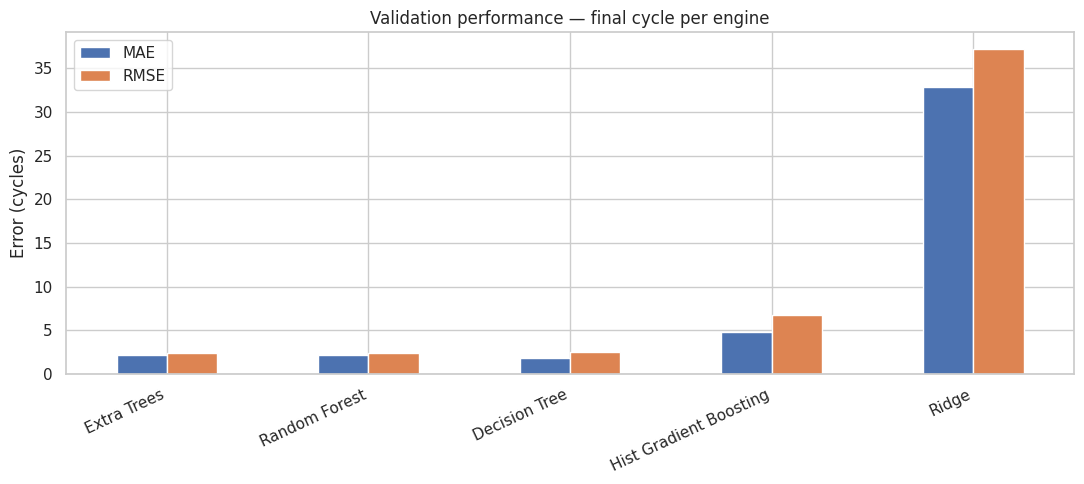

In [17]:
ax = comparison[["MAE", "RMSE"]].plot(kind="bar", figsize=(11, 5))
ax.set_title("Validation performance — final cycle per engine")
ax.set_ylabel("Error (cycles)")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 8. Hyperparameter tuning with GroupKFold

Tune the strongest practical tree model on the training subset only. `GroupKFold` keeps all rows from an engine in the same fold. GridSearchCV's RMSE is row-level CV RMSE; the held-out validation score above is final-cycle-per-engine RMSE, so interpret the two metrics according to their evaluation unit.

In [18]:
cv = GroupKFold(n_splits=5)

tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE
    ))
])

param_grid = {
    "model__max_depth": [None, 12, 20],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": [0.5, 0.8],
}

search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train, groups=groups_train)

print("Best parameters:", search.best_params_)
print("Best CV RMSE (row-level):", -search.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'model__max_depth': 12, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}
Best CV RMSE (row-level): 40.63540705086449


In [19]:
tuned_model = search.best_estimator_
tuned_val_pred = tuned_model.predict(X_val_final)
tuned_val_metrics = regression_metrics(y_val_final, tuned_val_pred)

print("Tuned model — validation final-cycle metrics")
display(pd.DataFrame([tuned_val_metrics], index=["Tuned Random Forest"]))

Tuned model — validation final-cycle metrics


,MAE,RMSE,R2
Tuned Random Forest,2.173425,2.336348,0.0


## 9. Validation diagnostics

Check prediction quality and residual patterns before opening the official test set.

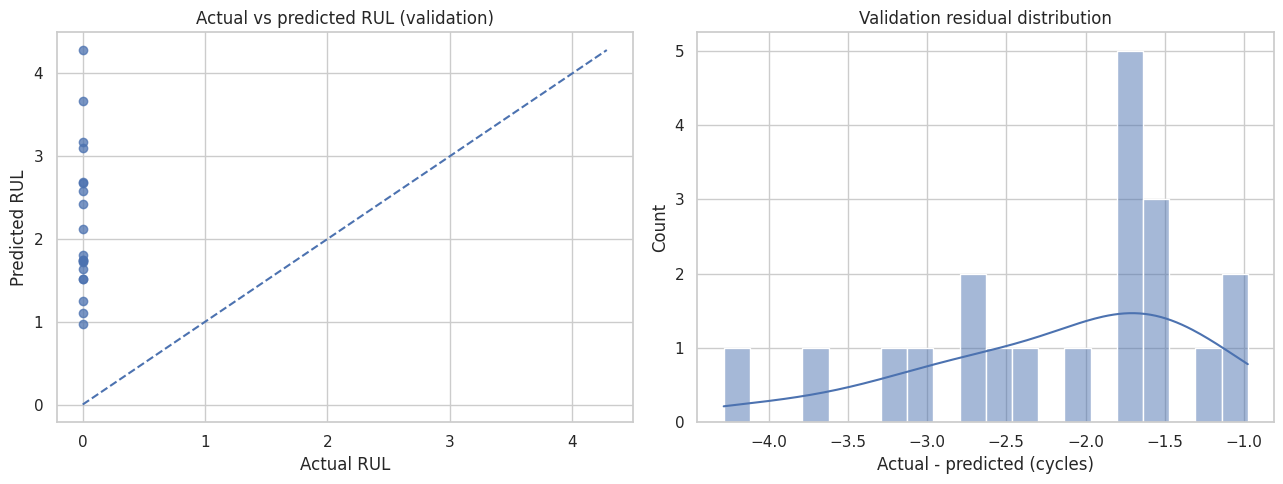

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_val_final, tuned_val_pred, alpha=0.75)
lims = [
    min(y_val_final.min(), tuned_val_pred.min()),
    max(y_val_final.max(), tuned_val_pred.max())
]
axes[0].plot(lims, lims, "--")
axes[0].set(title="Actual vs predicted RUL (validation)", xlabel="Actual RUL", ylabel="Predicted RUL")

residuals = y_val_final.to_numpy() - tuned_val_pred
sns.histplot(residuals, bins=20, kde=True, ax=axes[1])
axes[1].set(title="Validation residual distribution", xlabel="Actual - predicted (cycles)")

plt.tight_layout()
plt.show()

## 10. Prepare the official NASA test set

For every test engine:
- Build features from its observed test history.
- Keep only its final observed cycle.
- Pair that row with the corresponding value in `RUL_FD001.txt`.

The test RUL file has one label per test engine. We verify row counts and engine ordering before evaluation.

In [21]:
# Generate test features with exactly the same feature columns and order.
X_test_all = make_features(test_df, base_features)

test_last_rows = (
    test_df.sort_values(["unit_number", "time_cycles"])
    .groupby("unit_number", sort=True)
    .tail(1)
    .sort_values("unit_number")
    .reset_index(drop=True)
)

# Get feature rows corresponding to each engine's final observed cycle.
test_feature_frame = X_test_all.copy()
test_feature_frame["_unit_number"] = test_df.sort_values(
    ["unit_number", "time_cycles"]
).reset_index(drop=True)["unit_number"].to_numpy()
test_feature_frame["_time_cycles"] = test_df.sort_values(
    ["unit_number", "time_cycles"]
).reset_index(drop=True)["time_cycles"].to_numpy()

test_final_features = (
    test_feature_frame.sort_values(["_unit_number", "_time_cycles"])
    .groupby("_unit_number", sort=True)
    .tail(1)
    .drop(columns=["_unit_number", "_time_cycles"])
    .reset_index(drop=True)
)

y_test_final = rul_test["RUL"].astype(float).reset_index(drop=True)

assert len(test_final_features) == len(y_test_final), (
    f"Mismatch: {len(test_final_features)} test engines vs {len(y_test_final)} RUL labels"
)
assert len(test_final_features.columns) == len(X_train.columns)
test_final_features = test_final_features[X_train.columns]

print("Final test feature shape:", test_final_features.shape)
print("Official test labels:", y_test_final.shape)
display(pd.DataFrame({"true_RUL": y_test_final}).head())

Final test feature shape: (100, 137)
Official test labels: (100,)


,true_RUL
0,112.0
1,98.0
2,69.0
3,82.0
4,91.0


## 11. Final test evaluation

We now evaluate the tuned model on the official test set. This is the final held-out benchmark evaluation; do not tune model parameters using these results.

In [22]:
test_pred = tuned_model.predict(test_final_features)
test_metrics = regression_metrics(y_test_final, test_pred)

print("OFFICIAL TEST RESULTS")
display(pd.DataFrame([test_metrics], index=["Tuned Random Forest — NASA FD001 test"]))

OFFICIAL TEST RESULTS


,MAE,RMSE,R2
Tuned Random Forest — NASA FD001 test,18.090568,25.951558,0.609998


,engine_id,actual_RUL,predicted_RUL,absolute_error
0,1,112.0,187.316747,75.316747
1,2,98.0,158.720054,60.720054
2,3,69.0,49.612633,19.387367
3,4,82.0,81.466016,0.533984
4,5,91.0,91.932095,0.932095
5,6,93.0,102.556567,9.556567
6,7,91.0,101.830713,10.830713
7,8,95.0,83.481778,11.518222
8,9,111.0,145.623255,34.623255
9,10,96.0,110.092618,14.092618


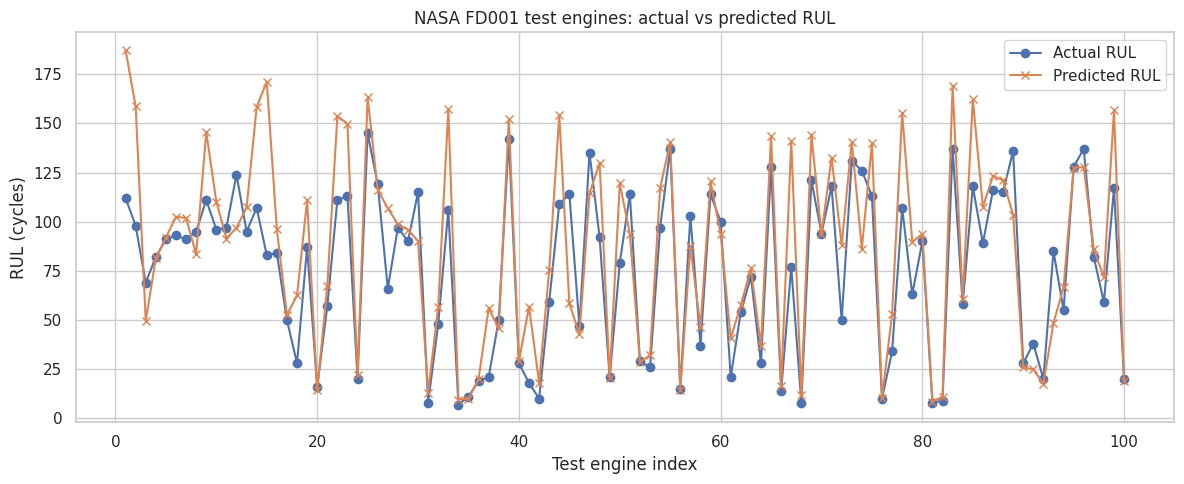

In [23]:
test_results = pd.DataFrame({
    "engine_id": np.arange(1, len(y_test_final) + 1),
    "actual_RUL": y_test_final,
    "predicted_RUL": test_pred
})
test_results["absolute_error"] = (test_results["actual_RUL"] - test_results["predicted_RUL"]).abs()
display(test_results.head(15))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test_results["engine_id"], test_results["actual_RUL"], marker="o", label="Actual RUL")
ax.plot(test_results["engine_id"], test_results["predicted_RUL"], marker="x", label="Predicted RUL")
ax.set(title="NASA FD001 test engines: actual vs predicted RUL", xlabel="Test engine index", ylabel="RUL (cycles)")
ax.legend()
plt.tight_layout()
plt.show()

## 12. Maintenance alert analysis

The project brief suggests an alert when predicted RUL is below 30 cycles. We report precision and recall for this threshold on the official test set. This is an illustrative decision threshold for the project, not an operational aviation maintenance rule.

In [24]:
ALERT_THRESHOLD = 30

actual_alert = (y_test_final < ALERT_THRESHOLD).astype(int)
predicted_alert = (test_pred < ALERT_THRESHOLD).astype(int)

tp = int(((actual_alert == 1) & (predicted_alert == 1)).sum())
fp = int(((actual_alert == 0) & (predicted_alert == 1)).sum())
fn = int(((actual_alert == 1) & (predicted_alert == 0)).sum())

precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0

alert_report = pd.DataFrame([{
    "threshold_cycles": ALERT_THRESHOLD,
    "true_alerts": int(actual_alert.sum()),
    "predicted_alerts": int(predicted_alert.sum()),
    "true_positives": tp,
    "false_positives": fp,
    "false_negatives": fn,
    "precision": precision,
    "recall": recall
}])
display(alert_report)

,threshold_cycles,true_alerts,predicted_alerts,true_positives,false_positives,false_negatives,precision,recall
0,30,25,20,19,1,6,0.95,0.76


## 13. Feature importance

Permutation importance is computed on the validation final-cycle rows. It estimates how much the validation score worsens when a feature is shuffled. Correlated features can share or mask importance, so interpret this as a diagnostic rather than a causal explanation.

,feature,importance_mean,importance_std
108,sensor_14_rollstd_20,0.139773,0.064835
0,time_cycles,0.040301,0.014993
106,sensor_14_rollstd_10,0.034254,0.022739
47,sensor_4_rollmean_5,0.029264,0.087486
80,sensor_9_rollstd_20,0.021951,0.004059
112,sensor_15_rollmean_10,0.019708,0.007483
133,sensor_21_rollmean_10,0.015070,0.007270
82,sensor_11_rollmean_5,0.014071,0.006306
52,sensor_4_rollstd_20,0.014041,0.003359
73,sensor_8_rollstd_20,0.009512,0.018020


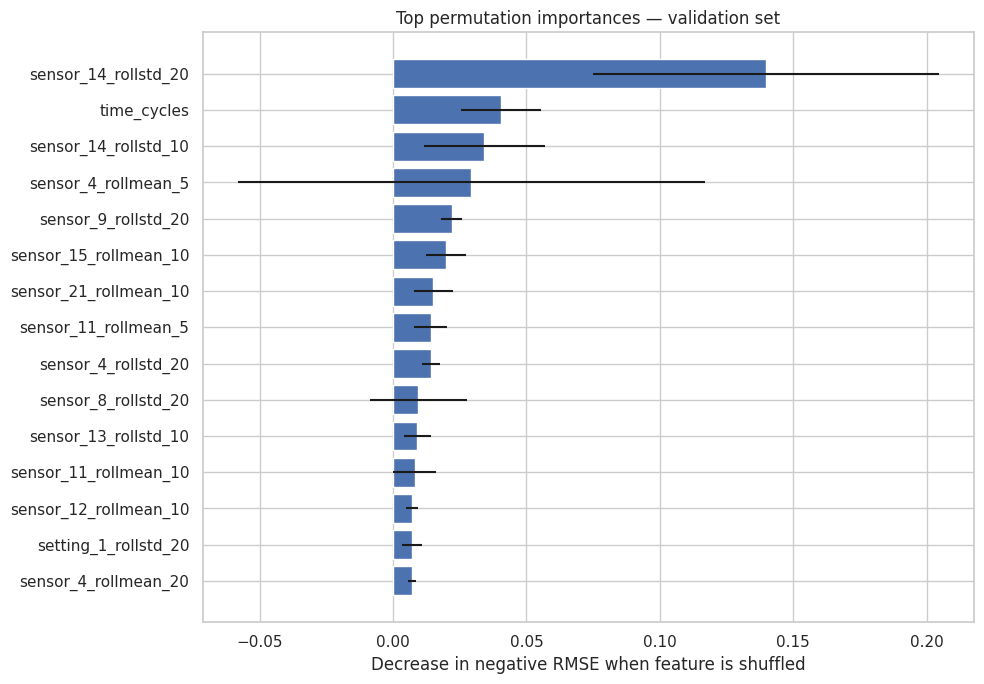

In [25]:
perm = permutation_importance(
    tuned_model,
    X_val_final,
    y_val_final,
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance = pd.DataFrame({
    "feature": X_val_final.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance.head(20))

top_imp = importance.head(15).sort_values("importance_mean")
plt.figure(figsize=(10, 7))
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.title("Top permutation importances — validation set")
plt.xlabel("Decrease in negative RMSE when feature is shuffled")
plt.tight_layout()
plt.show()

## 14. Business interpretation and limitations

Use the actual metrics and plots from this notebook to write your final findings. Discuss:
- How many cycles ahead the model is typically wrong (MAE).
- The size of larger errors (RMSE penalizes large errors more).
- Whether the model systematically over- or under-predicts.
- Precision/recall trade-off for the example alert threshold.
- Which sensor-derived features appear most informative.

**Limitations**
1. C-MAPSS is simulated degradation data, not real aircraft fleet data.
2. FD001 represents one operating condition and one fault mode, so generalization is limited.
3. Test labels are provided only for the final observed cycle of each test engine.
4. A prediction is not a certified maintenance decision. Real-world use requires validation, domain review, safety processes, and operational data.
5. This notebook uses a row-level supervised target but evaluates final-cycle predictions to match the official test format.


## 15. Save trained model and metadata

The model is trained on engineered features. We save the feature names, base input columns, and alert threshold so the app can reproduce the same feature pipeline.

In [26]:
ARTIFACT_DIR = Path("/content/rul_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(tuned_model, ARTIFACT_DIR / "rul_model.joblib")
joblib.dump({
    "base_features": base_features,
    "model_features": list(X_train.columns),
    "alert_threshold": ALERT_THRESHOLD,
    "dataset_subset": "FD001",
    "target_definition": "uncapped RUL"
}, ARTIFACT_DIR / "metadata.joblib")

test_results.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)
importance.to_csv(ARTIFACT_DIR / "permutation_importance.csv", index=False)

print("Saved artifacts to:", ARTIFACT_DIR)
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Saved artifacts to: /content/rul_artifacts
['metadata.joblib', 'permutation_importance.csv', 'rul_model.joblib', 'test_predictions.csv']


## 16. Create a Streamlit application

The app accepts a CSV containing one engine's chronological sensor history. It builds the same current/rolling/difference features and predicts RUL for the latest row.

Expected CSV columns: `time_cycles`, all retained `setting_*` and `sensor_*` columns. `unit_number` is optional; if present, the app uses the selected engine's rows.

The next cell writes `app.py` into the artifact folder.

In [27]:
app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

st.set_page_config(page_title="Jet Engine RUL Predictor", page_icon="✈️", layout="wide")
st.title("Jet Engine Remaining Useful Life Predictor")
st.caption("NASA C-MAPSS FD001 | Educational predictive-maintenance demo")

ARTIFACT_DIR = Path(__file__).parent
model = joblib.load(ARTIFACT_DIR / "rul_model.joblib")
meta = joblib.load(ARTIFACT_DIR / "metadata.joblib")
base_features = meta["base_features"]
model_features = meta["model_features"]
alert_threshold = meta["alert_threshold"]

def make_features(df, sensor_setting_columns, windows=(5, 10, 20)):
    out = df[["time_cycles"] + sensor_setting_columns].copy()
    out = out.sort_values("time_cycles").reset_index(drop=True)
    for col in sensor_setting_columns:
        out[f"{col}_diff1"] = out[col].diff(1)
        for window in windows:
            roll = out[col].rolling(window=window, min_periods=1)
            out[f"{col}_rollmean_{window}"] = roll.mean()
            out[f"{col}_rollstd_{window}"] = roll.std()
    return out.drop(columns=["time_cycles"])

uploaded = st.file_uploader("Upload one engine history (CSV)", type=["csv"])

if uploaded is not None:
    data = pd.read_csv(uploaded)
    if "unit_number" in data.columns:
        engine_options = sorted(data["unit_number"].dropna().unique().tolist())
        selected_engine = st.selectbox("Engine", engine_options)
        data = data[data["unit_number"] == selected_engine].copy()

    missing = [c for c in base_features if c not in data.columns]
    if missing:
        st.error("Missing required columns: " + ", ".join(missing))
    elif data.empty:
        st.error("No rows found for the selected engine.")
    else:
        data = data.sort_values("time_cycles").reset_index(drop=True)
        feats = make_features(data, base_features)
        latest = feats.iloc[[-1]].reindex(columns=model_features)
        prediction = max(0.0, float(model.predict(latest)[0]))

        c1, c2 = st.columns(2)
        c1.metric("Predicted remaining life", f"{prediction:.1f} cycles")
        if prediction < alert_threshold:
            c2.error(f"Maintenance review alert: below {alert_threshold} cycles")
        else:
            c2.success(f"No threshold alert: at or above {alert_threshold} cycles")

        st.subheader("Sensor history")
        sensor_to_plot = st.selectbox(
            "Sensor to visualize",
            [c for c in base_features if c.startswith("sensor_")]
        )
        st.line_chart(data.set_index("time_cycles")[[sensor_to_plot]])

        st.info(
            "Educational prototype only. This prediction is not a certified "
            "aviation maintenance recommendation."
        )
else:
    st.write("Upload a CSV containing chronological sensor readings for one engine.")
'''

app_path = ARTIFACT_DIR / "app.py"
app_path.write_text(app_code, encoding="utf-8")
print("Created:", app_path)

Created: /content/rul_artifacts/app.py


### 16.1 Package the app files

Download the ZIP, then deploy it using Streamlit Community Cloud or run locally. The ZIP includes `app.py`, the trained model, and metadata. You must add a `requirements.txt` when deploying.

In [28]:
requirements = '''streamlit\npandas\nnumpy\nscikit-learn\njoblib\n'''
(ARTIFACT_DIR / "requirements.txt").write_text(requirements, encoding="utf-8")

zip_path = Path("/content/Jet_Engine_RUL_Streamlit_App.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in ARTIFACT_DIR.iterdir():
        if file.is_file():
            zf.write(file, arcname=file.name)

print("App package:", zip_path)
print("Files:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

App package: /content/Jet_Engine_RUL_Streamlit_App.zip
Files: ['app.py', 'metadata.joblib', 'permutation_importance.csv', 'requirements.txt', 'rul_model.joblib', 'test_predictions.csv']


## 17. Final project checklist

- [ ] Dataset source and subset (FD001) documented
- [ ] Data quality and EDA completed
- [ ] RUL target created only for training trajectories
- [ ] Features use current/past observations only
- [ ] Constant features removed based on training data
- [ ] Split performed by engine ID
- [ ] At least three classical ML algorithms compared
- [ ] Hyperparameter tuning performed only on training engines
- [ ] Official test set evaluated once after model selection
- [ ] Metrics and plots copied from actual notebook output
- [ ] Limitations and simulated-data caveat included
- [ ] Streamlit app packaged and tested

## References
1. NASA Open Data Portal — [CMAPSS Jet Engine Simulated Data](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data)
2. NASA Prognostics Center of Excellence — [Turbofan Engine Degradation Simulation Data Set](https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip)
3. Scikit-learn — [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
4. Scikit-learn — [GroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html)
5. Scikit-learn — [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)

**Citation for the dataset:** A. Saxena and K. Goebel (2008), *Turbofan Engine Degradation Simulation Data Set*, NASA Prognostics Data Repository, NASA Ames Research Center.


In [30]:
import shutil

shutil.make_archive(
    "/content/Jet_Engine_RUL_App",
    "zip",
    "/content/rul_artifacts"
)

from google.colab import files

files.download("/content/Jet_Engine_RUL_App.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>